# 02 · Forecasters: cut risk and demand, +1/+2/+4 h (pooled training data)

Recipe fixed in `results/FINAL_SPEC.md` §3 (the v1/v2 recipe, unchanged):
- **Cut risk per home:** CatBoost (+1 h, +2 h) / XGBoost (+4 h) classifiers on the v2 features (no `cut_now`), fit on a 50% sample of
  train-core, early stopping on the hold-out, isotonic calibration on the hold-out.
- **Demand per home:** LightGBM quantile regression (median), early stopping on the hold-out.
- **Hold-out:** the last 15% (by time) of each region's TRAIN period. **Gate** on VALIDATION: ≥ 5% better than the best simple baseline at
  +1 h and +2 h; a failing forecaster is replaced by its best baseline.
Pune is not read here.

In [1]:
%%writefile ../src/features.py
"""Causal forecaster inputs and the simulator's input arrays. Written from notebooks/02_forecasters.ipynb.
Feature definitions are those of versions 1-3 (archived src/features.py); every input at time t uses only data up to t."""
import numpy as np
import pandas as pd

SPD = 96
H = {"1h": 4, "2h": 8, "4h": 16}
CUT_F = ["into_min", "since_min", "share_1h", "share_24h", "share_7d", "home_slot7", "city_now", "city_1h",
         "city_slot7", "tod_sin", "tod_cos", "dow_sin", "dow_cos", "mon_sin", "mon_cos", "weekend"]       # v2: without cut_now
LOAD_F = ["d_now", "d_l1", "d_l4", "d_l8", "d_mean24", "d_yday_tgt", "d_week_tgt", "cut_now", "temp",
          "tod_sin", "tod_cos", "dow_sin", "dow_cos", "mon_sin", "mon_cos", "weekend"]


def runs_into_since(cut):
    x = np.nan_to_num(cut.values, nan=0.0); into = np.zeros_like(x); since = np.zeros_like(x)
    a = np.zeros(x.shape[1]); b = np.zeros(x.shape[1])
    for t in range(x.shape[0]):
        on = x[t] == 1; a = np.where(on, a + 1, 0); b = np.where(on, 0, np.minimum(b + 1, 30 * SPD))
        into[t], since[t] = a, b
    return pd.DataFrame(into * 15, cut.index, cut.columns), pd.DataFrame(since * 15, cut.index, cut.columns)


def target_time(idx, h):
    tt = idx + pd.Timedelta(minutes=15 * h); k = tt.hour * 4 + tt.minute // 15
    return pd.DataFrame({"tod_sin": np.sin(2 * np.pi * k / SPD), "tod_cos": np.cos(2 * np.pi * k / SPD),
                         "dow_sin": np.sin(2 * np.pi * tt.dayofweek / 7), "dow_cos": np.cos(2 * np.pi * tt.dayofweek / 7),
                         "mon_sin": np.sin(2 * np.pi * (tt.month - 1) / 12), "mon_cos": np.cos(2 * np.pi * (tt.month - 1) / 12),
                         "weekend": (tt.dayofweek >= 5).astype(float)}, index=idx)


def _long(frames):
    return pd.DataFrame({k: v.stack(future_stack=True) for k, v in frames.items()})


def cut_table(cut, h, into, since, ok_slot=None):
    idx = cut.index
    city_now = cut.mean(axis=1)
    home_slot7 = sum(cut.shift(SPD * k - h) for k in range(1, 8)) / 7
    city_slot7 = sum(city_now.shift(SPD * k - h) for k in range(1, 8)) / 7
    frames = {"cut_now": cut, "into_min": into, "since_min": since,
              "share_1h": cut.rolling(4, min_periods=2).mean(), "share_24h": cut.rolling(96, min_periods=48).mean(),
              "share_7d": cut.rolling(672, min_periods=300).mean(), "home_slot7": home_slot7, "y": cut.shift(-h)}
    if ok_slot is not None:
        frames.update({"ok_t": ok_slot, "ok_tt": ok_slot.shift(-h)})
    X = _long(frames)
    t = X.index.get_level_values(0)
    for name, s in {"city_now": city_now, "city_1h": city_now.rolling(4).mean(), "city_slot7": city_slot7}.items():
        X[name] = s.reindex(t).values
    tf = target_time(idx, h).reindex(t); X[tf.columns] = tf.values
    X["hour_now"] = t.hour
    return X.astype(np.float32)


def load_table(demand, sup, cut, temp_std, scale, h, ok_slot=None):
    frames = {"d_now": demand / scale, "d_l1": demand.shift(1) / scale, "d_l4": demand.shift(4) / scale,
              "d_l8": demand.shift(8) / scale, "d_mean24": demand.rolling(96, min_periods=48).mean() / scale,
              "d_yday_tgt": demand.shift(SPD - h) / scale, "d_week_tgt": demand.shift(672 - h) / scale,
              "cut_now": cut, "scale": scale, "y_kw": sup.shift(-h)}
    if ok_slot is not None:
        frames.update({"ok_t": ok_slot, "ok_tt": ok_slot.shift(-h)})
    X = _long(frames)
    t = X.index.get_level_values(0)
    X["temp"] = temp_std.reindex(t).values
    tf = target_time(demand.index, h).reindex(t); X[tf.columns] = tf.values
    X["y"] = X.y_kw / X.scale
    return X.astype(np.float32)


def home_scale(sup, fallback):
    return sup.rolling(672, min_periods=24).mean().fillna(fallback).clip(lower=0.02)


def predict_cut(F, hn, X, cut_f=None):
    c = F["cut"][hn]
    return c["iso"].predict(c["model"].predict_proba(X[cut_f or F["cut_features"]])[:, 1])


def forecasts(tab, F, scalers, cut_f=None, load_f=None):
    """Per-slot, per-home forecasts at +1/+2/+4 h for one region: cut probability and demand (kW). Returns two arrays [T, N, 3].
    F = a frozen forecaster bundle {"cut": {h: {model, iso}}, "load": {h: {0.5: model}}, "cut_features", "load_features"}."""
    cut, dem, sup, solar = tab["cut"], tab["demand"], tab["supplied_load"], tab["solar"]
    into, since = runs_into_since(cut)
    temp_std = (solar.t2m.reindex(cut.index) - scalers["temperature_mean"]) / scalers["temperature_std"]
    scale = home_scale(sup, scalers["home_load_fallback_kw"])
    P, L = [], []
    for hn, h in H.items():
        Xc = cut_table(cut, h, into, since)
        P.append(pd.Series(predict_cut(F, hn, Xc, cut_f), index=Xc.index).unstack().reindex(index=cut.index, columns=cut.columns)); del Xc
        Xl = load_table(dem, sup, cut, temp_std, scale, h)
        lm = F["load"][hn][0.5]
        L.append(pd.Series(np.clip(lm.predict(Xl[load_f or F["load_features"]]), 0, None) * Xl.scale.values, index=Xl.index).unstack()
                 .reindex(index=cut.index, columns=cut.columns)); del Xl
    return (np.nan_to_num(np.stack([p.values for p in P], -1), nan=0.0).astype(np.float32),
            np.nan_to_num(np.stack([l.values for l in L], -1), nan=0.0).astype(np.float32))


def obs_inputs(tab):
    """Simulator inputs per slot: true solar (kW/kWp), last completed hour's solar, solar 24 h ago, city 7-day same-time cut rate."""
    idx = tab["cut"].index
    pv = tab["solar"].pv_kw_per_kwp.reindex(idx)
    pv_obs = (tab["hourly"].ghi / 1000 * 0.75).reindex(idx, method="ffill")
    pv_prev = pv.shift(SPD)
    share = tab["cut"].mean(axis=1)
    day = share.groupby([idx.normalize(), idx.hour * 4 + idx.minute // 15]).mean().unstack()
    rate = day.shift(1).rolling(7, min_periods=3).mean()
    cut_rate = pd.Series(rate.reindex(idx.normalize()).values[np.arange(len(idx)), (idx.hour * 4 + idx.minute // 15)], idx)
    return pv, pv_obs, pv_prev, cut_rate


def make_bank_region(tab, cut_p, load_fc, extra=None):
    """One region of the simulator bank (see sim.load_bank)."""
    idx = tab["cut"].index
    pv, pv_obs, pv_prev, cut_rate = obs_inputs(tab)
    B = {"start": np.datetime64(idx[0], "m"), "homes": list(tab["cut"].columns),
         "demand": tab["demand"].values.astype(np.float32), "cut": np.nan_to_num(tab["cut"].values, nan=0.0).astype(bool),
         "pv": pv.fillna(0).values.astype(np.float32), "pv_obs": pv_obs.fillna(0).values.astype(np.float32),
         "pv_prev": pv_prev.fillna(0).values.astype(np.float32),
         "cut_rate": cut_rate.fillna(cut_rate.mean()).values.astype(np.float32), "cut_p": cut_p, "load_fc": load_fc}
    B.update(extra or {})
    return B

Writing ../src/features.py


In [2]:
import sys, json, hashlib, pickle, datetime, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb, xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import CUT_F, LOAD_F, H, SPD, runs_into_since, cut_table, load_table, home_scale
PROC, RES = ROOT / "data" / "processed", ROOT / "results"
(ROOT / "models").mkdir(exist_ok=True)
assert hashlib.sha256((RES / "FINAL_SPEC.md").read_bytes()).hexdigest() == json.loads((RES / "FINAL_SPEC_lock.json").read_text())["sha256"], "plan changed"
split = json.loads((PROC / "split.json").read_text())
assert hashlib.sha256(json.dumps(split, indent=1).encode()).hexdigest() == json.loads((PROC / "split_lock.json").read_text())["sha256"], "split changed"
SC = split["scalers"]; REGIONS = ["Mathura", "Bareilly", "UP"]
TAB, PARTS = {}, {}
for r in REGIONS:
    TAB[r] = {k: pd.read_parquet(PROC / f"{r}_{k}.parquet") for k in ["cut", "demand", "supplied_load"]}
    TAB[r]["solar"] = pd.read_parquet(PROC / f"{r}_solar_15min.parquet")
    okd = pd.read_parquet(PROC / f"{r}_complete_days.parquet").astype(bool); idx = TAB[r]["cut"].index
    TAB[r]["ok_slot"] = okd.reindex(idx.normalize()).set_axis(idx).fillna(False).astype(float)
    TAB[r]["into"], TAB[r]["since"] = runs_into_since(TAB[r]["cut"])
    g = split["regions"][r]; end = lambda d: pd.Timestamp(d) + pd.Timedelta(hours=23, minutes=45)
    PARTS[r] = {"core": (pd.Timestamp(g["train"]["from"]), pd.Timestamp(g["train"]["holdout_from"]) - pd.Timedelta(minutes=15)),
                "hold": (pd.Timestamp(g["train"]["holdout_from"]), end(g["train"]["to"])),
                "val": (pd.Timestamp(g["val"]["from"]), end(g["val"]["to"]))}
display(pd.DataFrame({r: {k: f"{a.date()} - {b.date()}" for k, (a, b) in p.items()} for r, p in PARTS.items()}).T)

def part_rows(X, h, r):
    t = X.index.get_level_values(0); tt = t + pd.Timedelta(minutes=15 * h); out = {}
    for k, (a, b) in PARTS[r].items():
        out[k] = (t >= a) & (t <= b) & (tt >= a) & (tt <= b)
    return out

,core,hold,val
Mathura,2019-05-01 - 2020-06-17,2020-06-18 - 2020-08-31,2020-09-01 - 2021-02-20
Bareilly,2019-07-16 - 2020-10-10,2020-10-11 - 2020-12-31,2021-01-01 - 2021-10-31
UP,2019-03-15 - 2019-08-30,2019-08-31 - 2019-09-30,2019-10-01 - 2019-12-31


## 1. Cut-risk models

In [3]:
def fit_cut(name, Xc, yc, Xh, yh):
    if name == "CatBoost":
        return CatBoostClassifier(iterations=400, learning_rate=0.05, depth=6, verbose=0, thread_count=8, random_seed=0).fit(Xc, yc, eval_set=(Xh, yh), early_stopping_rounds=30)
    return xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, min_child_weight=50, n_jobs=8, early_stopping_rounds=30,
                             eval_metric="logloss", tree_method="hist").fit(Xc, yc, eval_set=[(Xh, yh)], verbose=False)
FAM = {"1h": "CatBoost", "2h": "CatBoost", "4h": "XGBoost"}
def brier(y, p): return float(np.mean((np.asarray(p) - np.asarray(y)) ** 2))
rng = np.random.default_rng(0); CUT, persist, cut_rows = {}, {}, []
for hn, h in H.items():
    t0 = time.time(); D = {"core": [], "hold": [], "val": []}
    for r in REGIONS:
        T_ = TAB[r]; X = cut_table(T_["cut"], h, T_["into"], T_["since"], T_["ok_slot"])
        X = X[(X.ok_t == 1) & (X.ok_tt == 1) & X.cut_now.notna() & X.y.notna()].drop(columns=["ok_t", "ok_tt"])
        m = part_rows(X, h, r)
        for k in D: D[k].append(X[m[k]].assign(region=r))
        del X
    D = {k: pd.concat(v) for k, v in D.items()}
    core = D["core"].iloc[np.sort(rng.choice(len(D["core"]), len(D["core"]) // 2, replace=False))]
    model = fit_cut(FAM[hn], core[CUT_F], core.y.astype(int), D["hold"][CUT_F], D["hold"].y.astype(int))
    iso = IsotonicRegression(out_of_bounds="clip").fit(model.predict_proba(D["hold"][CUT_F])[:, 1], D["hold"].y.astype(int))
    CUT[hn] = {"name": FAM[hn], "model": model, "iso": iso}
    tr = pd.concat([D["core"], D["hold"]]); persist[hn] = tr.groupby([tr.cut_now, tr.hour_now]).y.mean()
    va = D["val"]; y = va.y.values.astype(int)
    p = iso.predict(model.predict_proba(va[CUT_F])[:, 1])
    base = {"(a) city 7-day same time": va.city_slot7.fillna(va.city_now).clip(0, 1).values,
            "(b) home 7-day same time": va.home_slot7.fillna(va.city_slot7).fillna(0).clip(0, 1).values,
            "(c) persistence table": persist[hn].reindex(pd.MultiIndex.from_arrays([va.cut_now, va.hour_now])).fillna(y.mean()).values}
    bb = {k: brier(y, v) for k, v in base.items()}; best = min(bb, key=bb.get)
    row = {"horizon": hn, "model": FAM[hn], "train rows (50% core)": len(core), "validation rows": len(va), "Brier": brier(y, p),
           "best baseline": best, "Brier best baseline": bb[best], "improvement vs best (%)": 100 * (1 - brier(y, p) / bb[best]),
           "ROC-AUC": roc_auc_score(y, p), "ROC-AUC best baseline": roc_auc_score(y, base[best]), "base rate": y.mean()}
    for r in REGIONS:
        mr = (va.region == r).values; row[f"Brier {r}"] = brier(y[mr], p[mr])
    cut_rows.append(row); del D, core, tr, va
    print(f"{hn}: {FAM[hn]} fitted in {time.time() - t0:.0f}s")
cut_val = pd.DataFrame(cut_rows).set_index("horizon"); display(cut_val.round(4).T)

1h: CatBoost fitted in 56s


2h: CatBoost fitted in 43s


4h: XGBoost fitted in 38s


horizon,1h,2h,4h
model,CatBoost,CatBoost,XGBoost
train rows (50% core),1495310,1489532,1478138
validation rows,1404796,1399256,1388176
Brier,0.051,0.0563,0.0589
best baseline,(c) persistence table,(b) home 7-day same time,(b) home 7-day same time
Brier best baseline,0.0614,0.0654,0.0649
improvement vs best (%),16.9833,13.892,9.197
ROC-AUC,0.8935,0.8656,0.8448
ROC-AUC best baseline,0.8172,0.7655,0.7667
base rate,0.0849,0.0844,0.0838


## 2. Demand models (median)

In [4]:
LOAD, load_rows = {}, []
for hn, h in H.items():
    t0 = time.time(); D = {"core": [], "hold": []}; VALX = {}
    for r in REGIONS:
        T_ = TAB[r]
        temp_std = (T_["solar"].t2m.reindex(T_["cut"].index) - SC["temperature_mean"]) / SC["temperature_std"]
        scale = home_scale(T_["supplied_load"], SC["home_load_fallback_kw"])
        X = load_table(T_["demand"], T_["supplied_load"], T_["cut"], temp_std, scale, h, T_["ok_slot"])
        X = X[(X.ok_t == 1) & (X.ok_tt == 1) & X.d_now.notna()].drop(columns=["ok_t", "ok_tt"])
        m = part_rows(X, h, r)
        for k in D: D[k].append(X[m[k] & X.y.notna().values])
        VALX[r] = X[m["val"]]; del X
    D = {k: pd.concat(v) for k, v in D.items()}
    core = D["core"].iloc[np.sort(rng.choice(len(D["core"]), len(D["core"]) // 2, replace=False))]
    lm = lgb.LGBMRegressor(objective="quantile", alpha=0.5, n_estimators=400, learning_rate=0.05, num_leaves=63, min_child_samples=200,
                           verbose=-1, n_jobs=8).fit(core[LOAD_F], core.y, eval_set=[(D["hold"][LOAD_F], D["hold"].y)],
                                                     callbacks=[lgb.early_stopping(30, verbose=False)])
    LOAD[hn] = {0.5: lm}
    # validation: street (10 fixed homes) demand error, against yesterday and persistence
    em, ea, eb = [], [], []
    for r in REGIONS:
        X = VALX[r]; pred = pd.Series(lm.predict(X[LOAD_F]) * X.scale.values, index=X.index).unstack()
        sup, dem = TAB[r]["supplied_load"], TAB[r]["demand"]; vb = PARTS[r]["val"][1]
        for w in [w for w in split["val"] if w["region"] == r]:
            ix = pd.date_range(w["start"], periods=672, freq="15min"); hm = w["homes"]
            tt = ix + pd.Timedelta(minutes=15 * h); keep = tt <= vb; ix, tt = ix[keep], tt[keep]
            act = sup.reindex(tt)[hm].values; f = pred.reindex(index=ix, columns=hm).values
            fa = dem.reindex(tt - pd.Timedelta(days=1))[hm].values; fb = dem.reindex(ix)[hm].values
            ok = ~np.isnan(act) & ~np.isnan(f) & ~np.isnan(fa) & ~np.isnan(fb); S = lambda x: np.where(ok, x, 0).sum(1); k = ok.any(1)
            em.append((S(f) - S(act))[k]); ea.append((S(fa) - S(act))[k]); eb.append((S(fb) - S(act))[k])
    em, ea, eb = map(np.concatenate, (em, ea, eb))
    rr = {"horizon": hn, "trees": lm.best_iteration_, "MAE model (kW, street)": np.abs(em).mean(), "MAE (a) yesterday": np.abs(ea).mean(),
          "MAE (b) persistence": np.abs(eb).mean(), "RMSE model": np.sqrt((em ** 2).mean())}
    rr["best baseline"] = "(a) yesterday" if rr["MAE (a) yesterday"] <= rr["MAE (b) persistence"] else "(b) persistence"
    rr["improvement vs best (%)"] = 100 * (1 - rr["MAE model (kW, street)"] / min(rr["MAE (a) yesterday"], rr["MAE (b) persistence"]))
    load_rows.append(rr); del D, core, VALX
    print(f"{hn}: demand model fitted in {time.time() - t0:.0f}s")
load_val = pd.DataFrame(load_rows).set_index("horizon"); display(load_val.round(4).T)

1h: demand model fitted in 46s


2h: demand model fitted in 43s


4h: demand model fitted in 45s


horizon,1h,2h,4h
trees,400,400,400
"MAE model (kW, street)",0.6535,0.7063,0.7438
MAE (a) yesterday,0.819,0.8192,0.8184
MAE (b) persistence,0.759,0.9153,1.1171
RMSE model,1.0314,1.0993,1.1526
best baseline,(b) persistence,(a) yesterday,(a) yesterday
improvement vs best (%),13.9078,13.7791,9.1156


## 3. Gate and freeze

cut  : PASS -> used in the state and the shield
load : PASS -> used in the state and the shield
forecasters frozen: ad07774150319b17


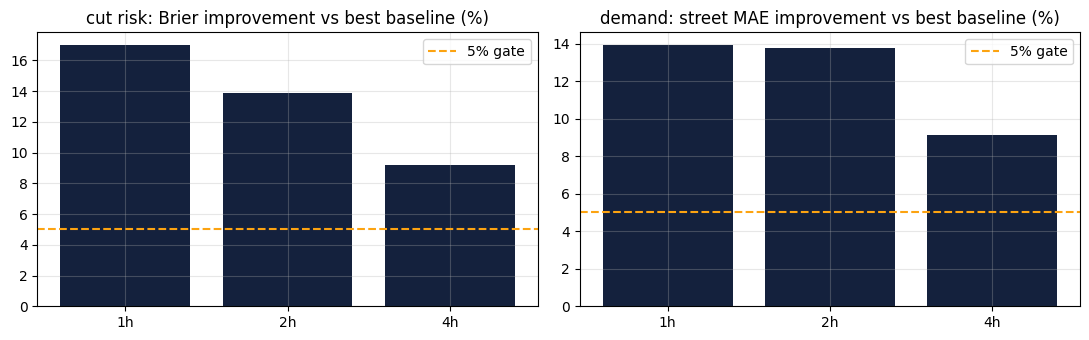

In [5]:
gate = {g: bool((tab.loc[["1h", "2h"], "improvement vs best (%)"] >= 5).all()) for g, tab in [("cut", cut_val), ("load", load_val)]}
bundle = {"cut": CUT, "cut_features": CUT_F, "load": LOAD, "load_features": LOAD_F, "persist_tables": persist, "gate": gate}
blob = pickle.dumps(bundle); (ROOT / "models" / "forecasters.pkl").write_bytes(blob)
out = {"frozen_at": datetime.datetime.now().isoformat(timespec="seconds"), "sha256": hashlib.sha256(blob).hexdigest(), "gate": gate,
       "cut_validation": cut_val.round(5).reset_index().to_dict(orient="records"), "load_validation": load_val.round(5).reset_index().to_dict(orient="records")}
(RES / "forecast_gate.json").write_text(json.dumps(out, indent=1, default=str))
for g, ok in gate.items():
    print(f"{g:5s}: {'PASS -> used in the state and the shield' if ok else 'FAIL -> replaced by its best baseline'}")
print("forecasters frozen:", out["sha256"][:16])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(cut_val.index, cut_val["improvement vs best (%)"], color="#14213D"); ax[0].set_title("cut risk: Brier improvement vs best baseline (%)")
ax[1].bar(load_val.index, load_val["improvement vs best (%)"], color="#14213D"); ax[1].set_title("demand: street MAE improvement vs best baseline (%)")
for a in ax: a.axhline(5, color="#FCA311", ls="--", label="5% gate"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RES / "figures" / "02_forecast_gate.png", dpi=130); plt.show()